# Predicción del nivel de desempeño - Pruebas Saber 11 (Medellín)
### Trabajo Integrador - Metodología CRISP-DM

Este notebook desarrolla, paso a paso, las 6 fases de CRISP-DM para construir
un modelo de **clasificación** que predice el nivel de desempeño de un colegio
en las Pruebas Saber 11 (Bajo, Medio, Alto, Superior), usando la versión
**depurada** del histórico de resultados publicado por la Alcaldía de Medellín
(Medata). Incluye, en cada fase, una explicación en lenguaje sencillo de lo
que significan los resultados.

Ana Milena Ibarbo G.


In [1]:
# Instalación de librerías
!pip install -q ydata-profiling scikit-learn==1.9.1 --upgrade


In [2]:
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
import json, warnings, os
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

for _carpeta in ["data", "figures", "models", "reports"]:
    os.makedirs(_carpeta, exist_ok=True)


## Cargar el dataset

Sube el archivo `historico_resultados_pruebas_saber_11_Depurado.csv`

In [3]:
from google.colab import files
import os

if not os.path.exists("data/historico_resultados_pruebas_saber_11_Depurado.csv"):
    print("Sube aquí el archivo historico_resultados_pruebas_saber_11_Depurado.csv")
    uploaded = files.upload()
    for nombre in uploaded:
        os.rename(nombre, "data/historico_resultados_pruebas_saber_11_Depurado.csv")


Sube aquí el archivo historico_resultados_pruebas_saber_11_Depurado.csv


Saving historico_resultados_pruebas_saber_11 Depurado.csv to historico_resultados_pruebas_saber_11 Depurado.csv


---
## Paso 0 · Corrección de codificación de texto

El archivo trae un problema técnico común: los acentos y la ñ quedaron mal
guardados (ej. "instituciÃ³n" en vez de "institución"). Lo arreglamos antes
de cualquier análisis.


In [4]:
# -*- coding: utf-8 -*-
"""
PASO 0 - CARGA Y CORRECCIÓN DE CODIFICACIÓN
=============================================
El archivo "Depurado" tiene un problema técnico de codificación de texto (los acentos y la ñ quedaron mal guardados, por
ejemplo "instituciÃ³n" en vez de "institución"). Esto es muy común cuando un archivo pasa por Excel o por herramientas distintas que no se ponen de
acuerdo en el "alfabeto" (codificación) que usan para guardar letras con tilde. Aquí lo arreglamos antes de empezar cualquier análisis.
"""
import pandas as pd

RAW_PATH = "data/historico_resultados_pruebas_saber_11_Depurado.csv"

df = pd.read_csv(RAW_PATH, encoding="latin1")


def arreglar_texto(valor):
    """Corrige el doble-mal-codificado típico de archivos CSV exportados
    desde Excel: el texto se guardó en UTF-8 pero se  leyó/guardó
    de nuevo como si fuera Latin-1. Revertimos ese paso."""
    if not isinstance(valor, str):
        return valor
    try:
        return valor.encode("latin1").decode("utf-8")
    except (UnicodeDecodeError, UnicodeEncodeError):
        return valor


for col in ["establecimiento", "comuna", "prestacion_servicio"]:
    df[col] = df[col].apply(arreglar_texto)

# Unificamos nombres de columnas al español sin mayúsculas ni tildes, para
# que coincidan con el resto del código (año_semestre se arma en la fase
# de preparación a partir de Año y Semestre).
df = df.rename(columns={"Año": "anio", "Semestre": "semestre"})

df.to_csv("data/dataset_corregido.csv", index=False, encoding="utf-8-sig")
print("Dataset corregido guardado en data/dataset_corregido.csv")
print("Forma:", df.shape)
print(df.head(15).to_string())


Dataset corregido guardado en data/dataset_corregido.csv
Forma: (1660, 12)
    anio  semestre                                   establecimiento  matriculados  registros  presentes  publicados  puntaje_global    comuna prestacion_servicio  punt_global_med  punt_global_comu
0   2014         2  col gente unida jovenes por la paz-santo domingo          66.0         66         64          63           240.0   popular        contratacion       263.257481        244.055802
1   2014         2                      col fe y alegria santa maria          31.0         31         29          29           238.0   popular        contratacion       263.257481        244.055802
2   2014         2               institución educativa pequeña maria          73.0         73         73          73           232.0   popular        contratacion       263.257481        244.055802
3   2014         2                col sagrada familia aldea pablo vi          38.0         38         38          38           246.0 

---
## FASE 1 · Entendimiento del negocio

**Contexto del dataset:** histórico de resultados agregados a nivel de
COLEGIO (no de estudiante individual) de las Pruebas Saber 11 en Medellín,
grado 11, entre 2014-2 y 2018-2 (364 colegios, 1.660 filas colegio-periodo).
Esta versión ya viene depurada: solo trae variables de contexto
institucional, sin los puntajes por área.

**Problema predictivo:** dado un colegio y un periodo, con variables de
contexto institucional (sector, comuna, tamaño, participación y comparación
con promedios de ciudad/comuna), **predecir en qué nivel de desempeño**
(Bajo / Medio / Alto / Superior) caerá su puntaje global promedio.

**Objetivos de minería de datos:**
1. Identificar qué variables institucionales se asocian más con el
   desempeño (para apoyar decisiones de política educativa).
2. Construir un clasificador multiclase confiable y generalizable (medido
   en colegios nunca vistos).
3. Entregar una herramienta usable (app web) para simular escenarios.

**Diseño de la solución:**

| Tipo de análisis | Tipo de aprendizaje | Modelos propuestos | Métrica principal |
|---|---|---|---|
| Predictivo | Supervisado (clasificación) | Regresión Logística, KNN, Árbol de Decisión, Naive Bayes, SVM, Voting, Bagging, Boosting | F1-macro |

**En palabras simples:** queremos que el computador aprenda, mirando cientos
de colegios del pasado, a "adivinar" si un colegio va a salir bien, regular
o mal en el examen, SOLO con datos como su tamaño, su barrio y su tipo
(público/privado) — sin mirar las notas reales del examen, porque eso sería
hacer trampa.


---
## FASE 2 · Entendimiento de los datos

Construimos el diccionario de datos, aplicamos reglas de calidad lógicas,
observamos la distribución de la variable objetivo, graficamos la
descripción estadística de cada variable y documentamos sesgos.


In [5]:
import os
os.makedirs('reports', exist_ok=True)
os.makedirs('figures', exist_ok=True)
# -*- coding: utf-8 -*-
"""
FASE 2 - ENTENDIMIENTO DE LOS DATOS
====================================
Diccionario de datos, reglas de calidad, distribución de la variable objetivo, sesgos, y gráficos de la descripción estadística de TODAS las
variables (uno por variable: histograma si es numérica, barras si es categórica), para poder explicarle a alguien no técnico qué forma tienen
los datos antes de tocarlos.
"""
import pandas as pd
import numpy as np
import json
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

df = pd.read_csv("data/dataset_corregido.csv")

resumen = {}
resumen["n_filas"] = int(df.shape[0])
resumen["n_columnas"] = int(df.shape[1])
resumen["n_establecimientos_unicos"] = int(df["establecimiento"].nunique())
resumen["n_periodos"] = int(df[["anio", "semestre"]].drop_duplicates().shape[0])

# ------------------------------------------------------------------
# 1. DICCIONARIO DE DATOS
# ------------------------------------------------------------------
descripciones = {
    "anio": "Año calendario en que se presentó la prueba.",
    "semestre": "Semestre del año en que se presentó la prueba (normalmente 1 o 2; 3 es un caso raro/residual con solo 2 filas).",
    "establecimiento": "Nombre del colegio o institución educativa.",
    "matriculados": "Número de estudiantes de grado 11 matriculados en el colegio en ese periodo.",
    "registros": "Número de estudiantes que se inscribieron para presentar la prueba Saber 11.",
    "presentes": "Número de estudiantes que efectivamente llegaron a presentar la prueba.",
    "publicados": "Número de estudiantes cuyos resultados fueron publicados por el ICFES.",
    "puntaje_global": "Puntaje promedio GLOBAL del colegio en ese periodo (escala ICFES, aprox. 0 a 500). Esta es la base de nuestra variable a predecir.",
    "comuna": "Comuna o corregimiento de Medellín donde está ubicado el colegio.",
    "prestacion_servicio": "Tipo de colegio: oficial (público), privado, o contratación (público que delega en un operador privado).",
    "punt_global_med": "Puntaje global PROMEDIO de toda la ciudad de Medellín en ese mismo periodo (referencia de comparación).",
    "punt_global_comu": "Puntaje global promedio de la COMUNA donde está el colegio, en ese periodo (referencia de comparación).",
}

diccionario = []
for col in df.columns:
    diccionario.append({
        "variable": col,
        "descripcion": descripciones.get(col, ""),
        "tipo_pandas": str(df[col].dtype),
        "tipo_num_cat": "Numérica" if pd.api.types.is_numeric_dtype(df[col]) else "Categórica/Texto",
        "valores_unicos": int(df[col].nunique()),
        "porcentaje_nulos": round(100 * df[col].isna().mean(), 2),
        "ejemplo": str(df[col].dropna().iloc[0]) if df[col].notna().any() else None,
    })
dic_df = pd.DataFrame(diccionario)
dic_df.to_csv("reports/diccionario_de_datos.csv", index=False, encoding="utf-8-sig")
print("Diccionario de datos guardado en reports/diccionario_de_datos.csv")
print(dic_df.to_string(index=False))

# ------------------------------------------------------------------
# 2. REGLAS DE CALIDAD
# ------------------------------------------------------------------
reglas = []
viol = int(((df["puntaje_global"] < 0) | (df["puntaje_global"] > 500)).sum())
reglas.append({"regla": "puntaje_global debe estar entre 0 y 500", "violaciones": viol})
reglas.append({"regla": "registros >= presentes", "violaciones": int((df["registros"] < df["presentes"]).sum())})
reglas.append({"regla": "presentes >= publicados", "violaciones": int((df["presentes"] < df["publicados"]).sum())})
reglas.append({"regla": "matriculados > 0 cuando registros > 0", "violaciones": int(((df["matriculados"] == 0) & (df["registros"] > 0)).sum())})
sub = df[(df["matriculados"].notna()) & (df["matriculados"] > 0)]
reglas.append({"regla": "matriculados >= registros (se espera, no siempre aplica)",
               "violaciones": int((sub["matriculados"] < sub["registros"]).sum()),
               "nota": "posibles estudiantes de otras cohortes o reporte asincrónico"})
reglas.append({"regla": "comuna sin espacios en blanco al inicio/fin", "violaciones": int(df["comuna"].apply(lambda x: x != x.strip()).sum())})
reglas.append({"regla": "establecimiento + anio + semestre único (no duplicados)",
               "violaciones": int(df.duplicated(subset=["establecimiento", "anio", "semestre"]).sum())})
reglas.append({"regla": "punt_global_med > 0 (promedio de ciudad válido)", "violaciones": int((df["punt_global_med"] <= 0).sum())})

reglas_df = pd.DataFrame(reglas)
reglas_df.to_csv("reports/reglas_de_calidad.csv", index=False, encoding="utf-8-sig")
print("\nReglas de calidad:")
print(reglas_df.to_string(index=False))

# ------------------------------------------------------------------
# 3. DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
df["puntaje_global"].dropna().hist(bins=30, ax=axes[0], color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribución de puntaje_global (puntaje promedio por colegio)")
axes[0].set_xlabel("Puntaje global")
axes[0].set_ylabel("Cantidad de colegios-periodo")

df.boxplot(column="puntaje_global", by="prestacion_servicio", ax=axes[1])
axes[1].set_title("Puntaje global por tipo de colegio")
axes[1].set_xlabel("Tipo de prestación del servicio")
axes[1].set_ylabel("Puntaje global")
plt.suptitle("")
plt.tight_layout()
plt.savefig("figures/01_distribucion_objetivo.png", dpi=130)
print("\nGráfico de distribución guardado en figures/01_distribucion_objetivo.png")

desc_objetivo = df["puntaje_global"].describe().to_dict()
resumen["estadisticas_puntaje_global"] = {k: round(float(v), 2) for k, v in desc_objetivo.items()}
resumen["asimetria_puntaje_global"] = round(float(df["puntaje_global"].skew()), 3)

# ------------------------------------------------------------------
# 4. GRÁFICOS DE DESCRIPCIÓN ESTADÍSTICA DE CADA VARIABLE
# ------------------------------------------------------------------
# Un gráfico por variable: histograma si es numérica (muestra en qué rango de valores se concentran los datos), barras si es categórica
# (muestra cuántas veces aparece cada categoría).
numericas = ["matriculados", "registros", "presentes", "publicados",
             "puntaje_global", "punt_global_med", "punt_global_comu", "anio"]
categoricas = ["comuna", "prestacion_servicio", "semestre"]

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
axes = axes.flatten()
for i, col in enumerate(numericas):
    df[col].dropna().hist(bins=25, ax=axes[i], color="#4C72B0", edgecolor="white")
    axes[i].set_title(col)
    axes[i].set_ylabel("Frecuencia")
for j in range(len(numericas), len(axes)):
    axes[j].axis("off")
plt.suptitle("Distribución de cada variable numérica", fontsize=15)
plt.tight_layout()
plt.savefig("figures/02_distribucion_variables_numericas.png", dpi=130)
print("Gráfico guardado en figures/02_distribucion_variables_numericas.png")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
df["comuna"].value_counts().plot(kind="barh", ax=axes[0], color="#55A868")
axes[0].invert_yaxis()
axes[0].set_title("Cantidad de filas por comuna")

df["prestacion_servicio"].value_counts().plot(kind="bar", ax=axes[1], color="#C44E52")
axes[1].set_title("Cantidad de filas por sector")
axes[1].tick_params(axis="x", rotation=0)

df["semestre"].value_counts().sort_index().plot(kind="bar", ax=axes[2], color="#8172B2")
axes[2].set_title("Cantidad de filas por semestre")
axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("figures/03_distribucion_variables_categoricas.png", dpi=130)
print("Gráfico guardado en figures/03_distribucion_variables_categoricas.png")

# Tabla resumen de estadísticas descriptivas
desc_stats_df = df[numericas].describe().T.round(2)
desc_stats_df.to_csv("reports/descripcion_estadistica_variables.csv", encoding="utf-8-sig")
print("\nDescripción estadística de variables numéricas:")
print(desc_stats_df)

# ------------------------------------------------------------------
# 5. POSIBLES SESGOS
# ------------------------------------------------------------------
sesgos = []
conteo_comuna = df["comuna"].str.strip().str.lower().value_counts()
sesgos.append(f"La comuna con más registros tiene {conteo_comuna.max()} filas; la que menos, "
              f"{conteo_comuna.min()} filas. Comunas pequeñas como Santa Elena o Palmitas están muy "
              f"subrepresentadas frente a Robledo o Castilla, lo que puede hacer que el modelo "
              f"aprenda peor el comportamiento de esas comunas.")

medias_sector = df.groupby("prestacion_servicio")["puntaje_global"].mean().round(1).to_dict()
sesgos.append(f"El puntaje promedio por sector es {medias_sector}. La brecha entre privado y "
              f"oficial/contratación refleja una desigualdad estructural ya conocida en la educación "
              f"colombiana; el modelo puede terminar apoyándose fuertemente en el sector del colegio.")

pocos = df[df["presentes"] < 10]
sesgos.append(f"Hay {len(pocos)} filas (colegio-periodo) con menos de 10 estudiantes presentando "
              f"la prueba. El promedio de grupos tan pequeños es estadísticamente más inestable, "
              f"lo que introduce ruido en la variable objetivo para esos casos.")

conteo_periodo = df.groupby(["anio", "semestre"]).size()
sesgos.append(f"La cantidad de colegios reportados varía mucho por periodo: desde {conteo_periodo.min()} "
              f"hasta {conteo_periodo.max()} filas. Los periodos '2014-3', '2016-1', '2017-1' y '2018-1' "
              f"tienen muy pocas filas (posiblemente colegios de calendario B o datos incompletos), lo "
              f"que puede sesgar las comparaciones de esos periodos específicos.")

resumen["sesgos_detectados"] = sesgos

with open("reports/entendimiento_datos_resumen.json", "w", encoding="utf-8") as f:
    json.dump(resumen, f, ensure_ascii=False, indent=2)

print("\n--- SESGOS DETECTADOS ---")
for s in sesgos:
    print("-", s)
print("\nResumen completo guardado en reports/entendimiento_datos_resumen.json")


Diccionario de datos guardado en reports/diccionario_de_datos.csv
           variable                                                                                                                        descripcion tipo_pandas     tipo_num_cat  valores_unicos  porcentaje_nulos                                          ejemplo
               anio                                                                                       Año calendario en que se presentó la prueba.       int64         Numérica               5              0.00                                             2014
           semestre                    Semestre del año en que se presentó la prueba (normalmente 1 o 2; 3 es un caso raro/residual con solo 2 filas).       int64         Numérica               3              0.00                                                2
    establecimiento                                                                                        Nombre del colegio o institución educa

### Explicación en lenguaje sencillo - Fase 2

- **El diccionario de datos** es como una "ficha técnica" de cada columna:
  qué significa, si es un número o una categoría, y qué tan completa está.
- **Las reglas de calidad** son chequeos de sentido común (por ejemplo, "no
  puede haber más estudiantes presentes que inscritos"). Encontramos que
  casi todas se cumplen, salvo un puñado de filas con inconsistencias
  menores que corregimos más adelante.
- **La distribución del puntaje global** muestra que la mayoría de los
  colegios se agrupan entre 246 y 280 puntos, con pocos casos muy altos o
  muy bajos — es una campana con una colita hacia los puntajes altos
  (colegios privados de excelente desempeño).
- **Los gráficos de cada variable** (ver imágenes) muestran, por ejemplo,
  que la mayoría de los colegios son pequeños o medianos (pocos
  matriculados), que la mayoría de las filas son de colegios oficiales, y
  que casi todos los colegios presentan la prueba en el segundo semestre
  del año.
- **Los sesgos** nos advierten que el modelo puede "aprender" más sobre
  comunas grandes (como Robledo) que sobre comunas pequeñas (como Santa
  Elena), y que hay una brecha real de puntaje entre colegios privados y
  oficiales que el modelo reflejará, no inventará.


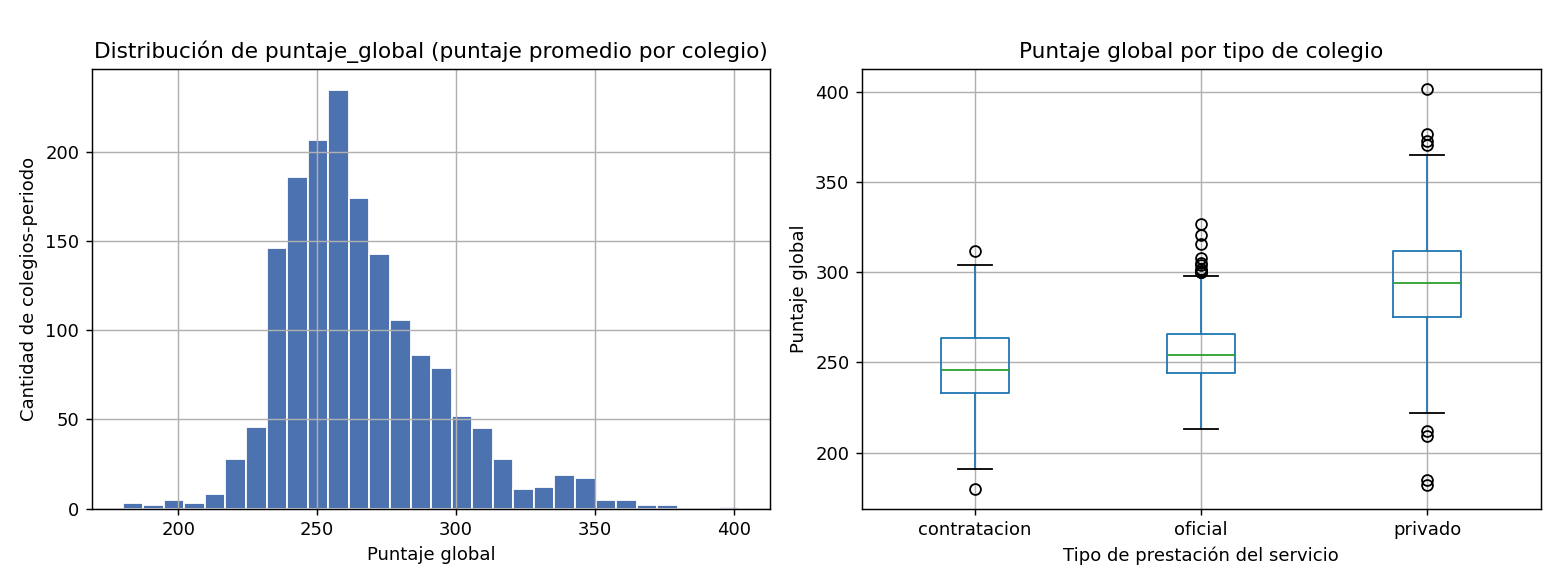

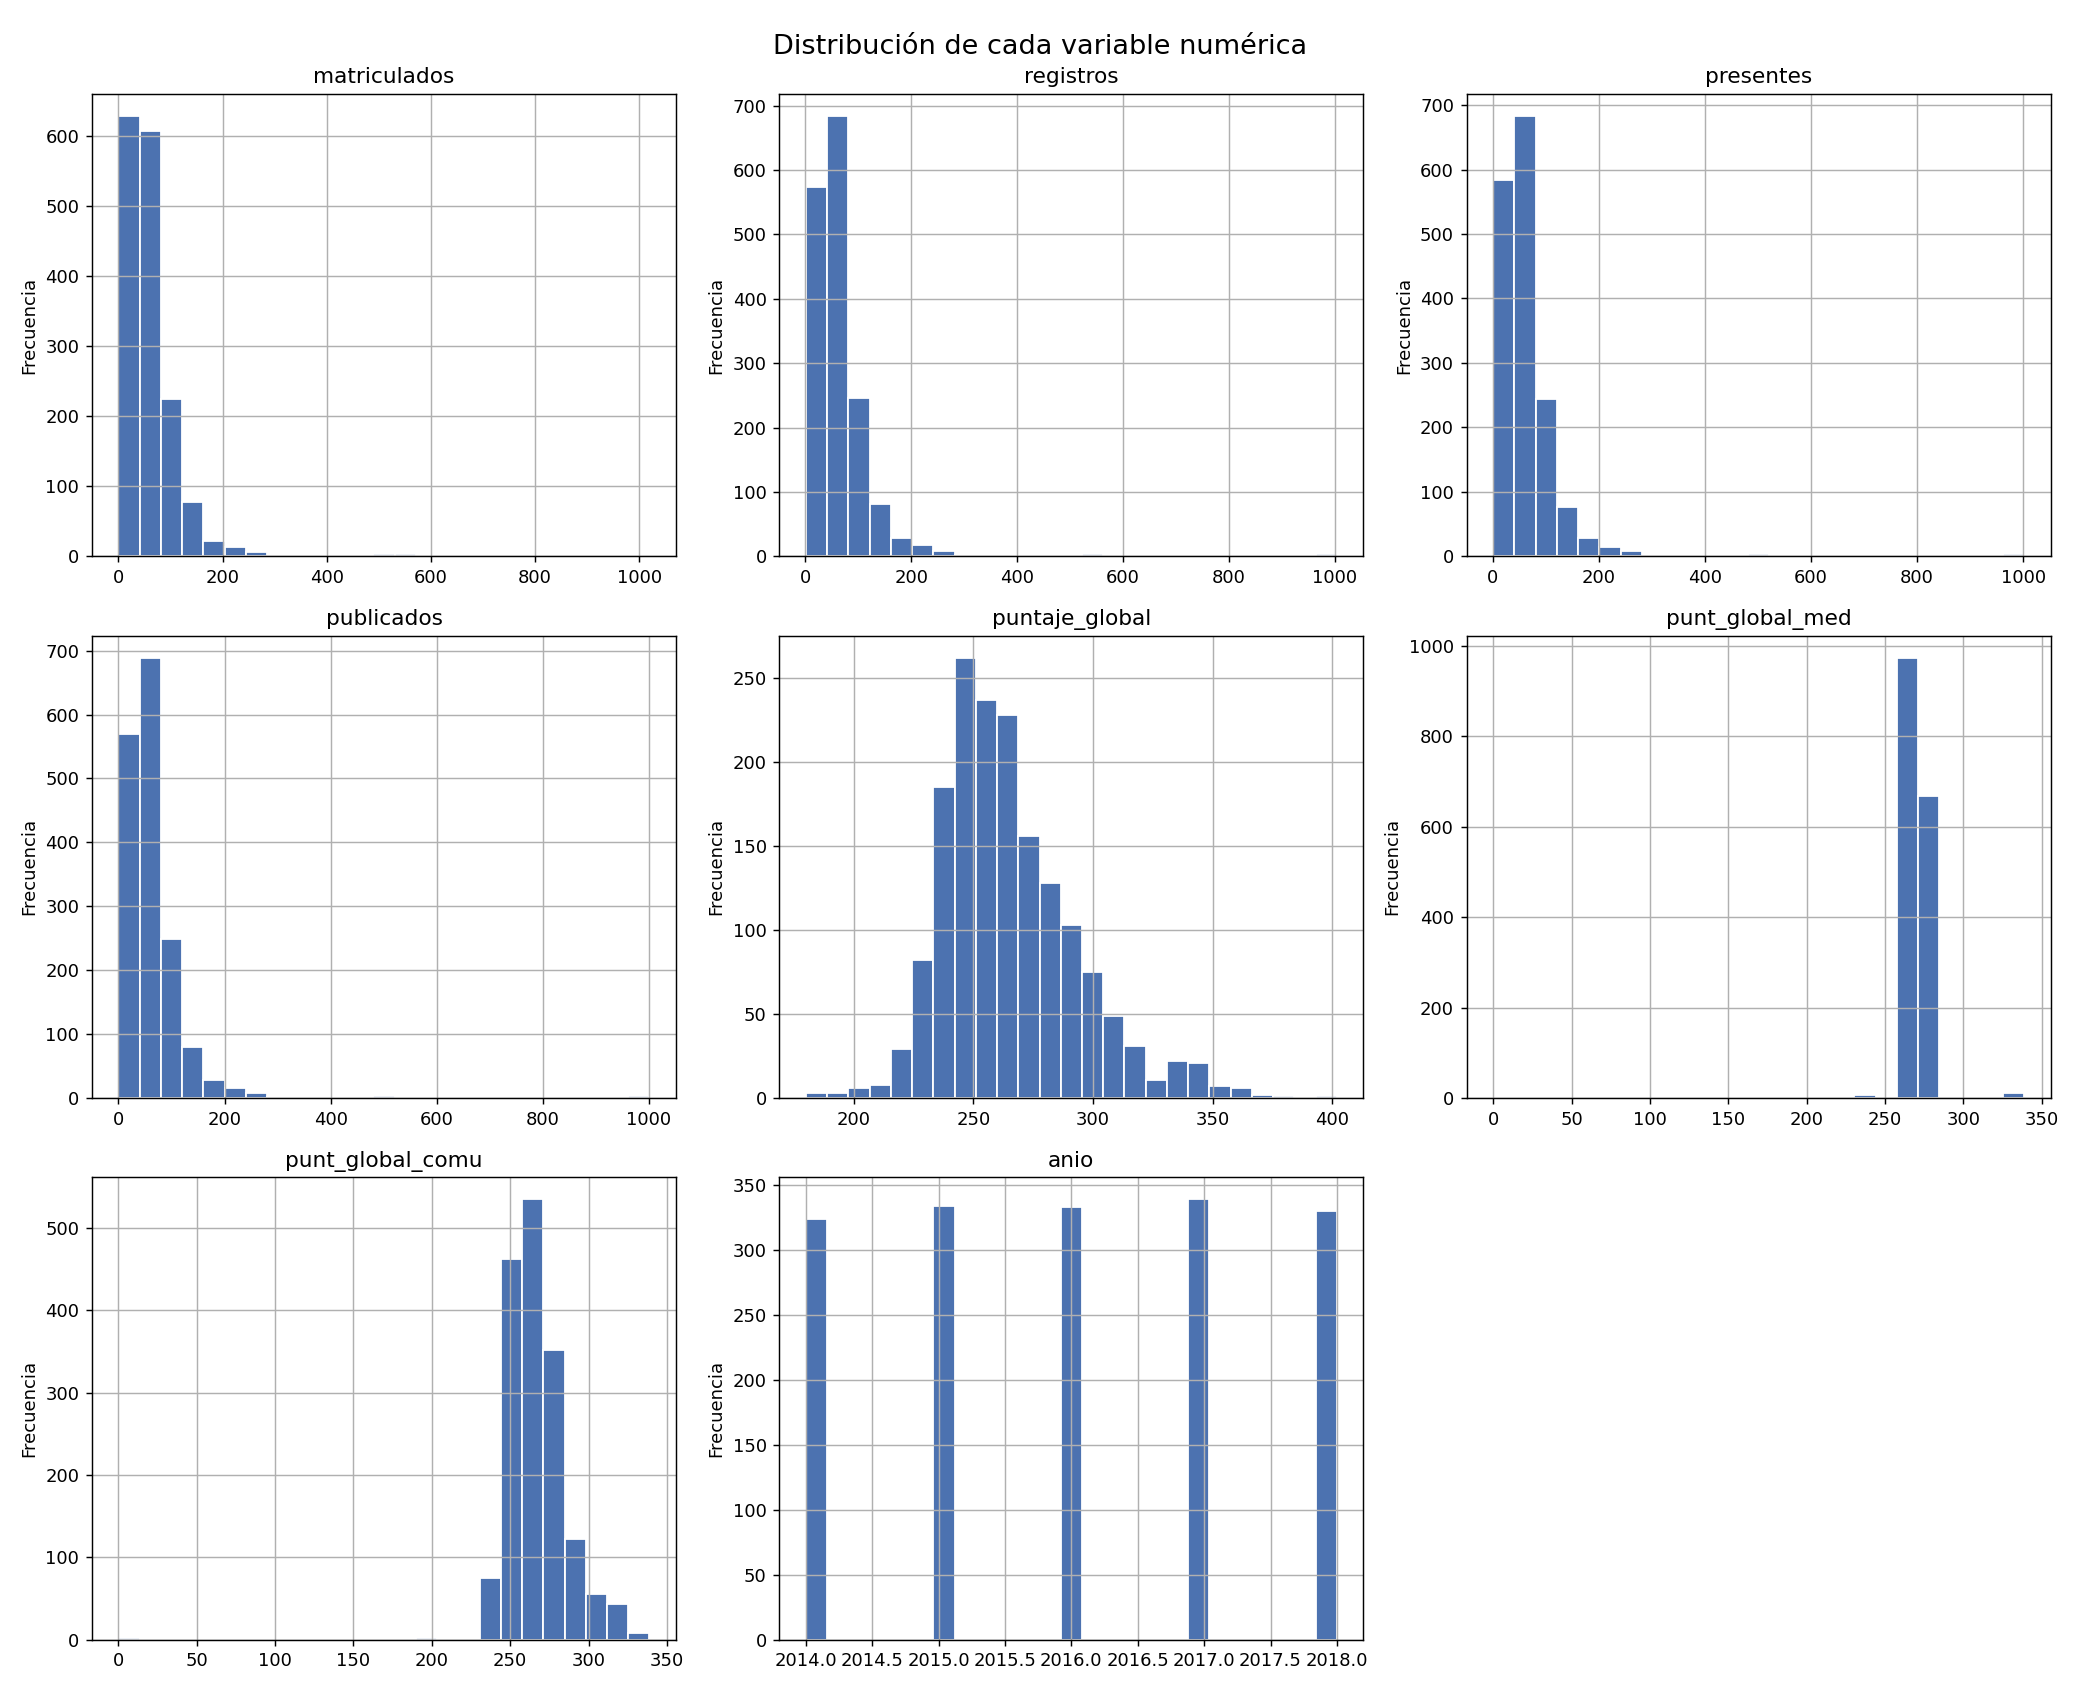

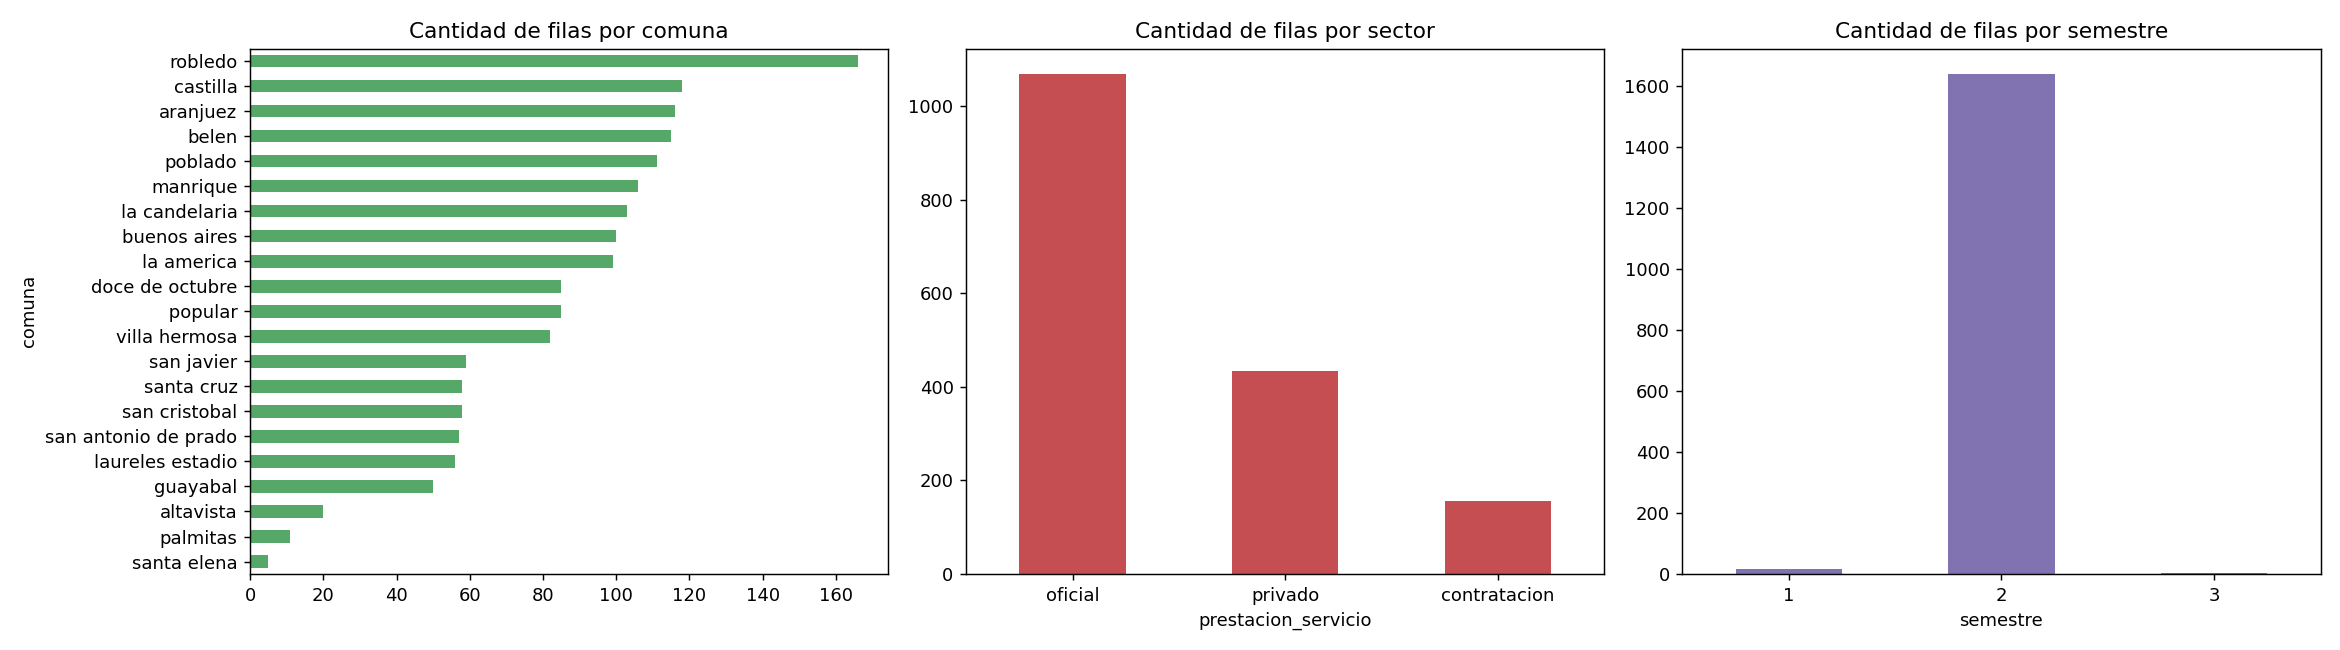

In [6]:
from IPython.display import Image, display
display(Image(filename="figures/01_distribucion_objetivo.png"))
display(Image(filename="figures/02_distribucion_variables_numericas.png"))
display(Image(filename="figures/03_distribucion_variables_categoricas.png"))


---
## FASE 3 · Preparación de los datos

Seleccionamos variables, generamos el reporte exploratorio con
`ydata-profiling`, limpiamos errores y nulos, creamos variables derivadas
y analizamos relaciones lineales y no lineales. Justificamos por qué NO se
aplica reducción de dimensiones ni balanceo.


In [7]:
# -*- coding: utf-8 -*-
"""
FASE 3 - PREPARACIÓN DE LOS DATOS
==================================
Este archivo "Depurado" ya viene sin los puntajes por área (lectura, matemáticas, etc.) ni las
columnas "ponderado" ni los promedios por sector. Es decir, el riesgo
de fuga de información aquí ya no existe: todas las columnas que quedan son variables de
contexto institucional, perfectamente usables como variables predictoras.
"""
import pandas as pd
import numpy as np
import json
import os

df = pd.read_csv("data/dataset_corregido.csv")

# ------------------------------------------------------------------
# 1. SELECCIÓN DE VARIABLES
# ------------------------------------------------------------------
variables_seleccionadas = {
    "anio": "Año de presentación; permite capturar tendencia temporal.",
    "semestre": "Semestre de presentación.",
    "comuna": "Ubicación del colegio; fuerte asociación con el desempeño educativo.",
    "prestacion_servicio": "Sector del colegio (oficial/privado/contratación); variable estructural clave en Colombia.",
    "matriculados": "Tamaño del colegio en grado 11.",
    "registros": "Cantidad de estudiantes inscritos a la prueba.",
    "presentes": "Cantidad de estudiantes que presentaron la prueba.",
    "publicados": "Cantidad de estudiantes con resultado publicado.",
    "punt_global_med": "Promedio de la ciudad ese periodo (referencia de contexto).",
    "punt_global_comu": "Promedio de la comuna ese periodo (referencia de contexto).",
}
variables_excluidas = ["establecimiento"]  # identificador, no aporta como predictor directo (demasiadas categorías únicas)
print("Variables predictoras seleccionadas:", list(variables_seleccionadas.keys()))
print("Variables excluidas (identificador):", variables_excluidas)
print("\nNota: este dataset YA viene depurado de columnas que causarían fuga de información "
      "(no trae puntajes por área ni promedios de sector), así que todas las variables de "
      "contexto disponibles se pueden usar como entrada sin riesgo.")

# ------------------------------------------------------------------
# 2. ELIMINAR FILAS SIN VARIABLE OBJETIVO
# ------------------------------------------------------------------
antes = len(df)
df = df[df["puntaje_global"].notna()].copy()
print(f"\nFilas sin puntaje_global eliminadas: {antes - len(df)}")

# ------------------------------------------------------------------
# 3. VARIABLE OBJETIVO (clasificación en 4 niveles, por cuartiles)
# ------------------------------------------------------------------
df["nivel_desempeno"] = pd.qcut(df["puntaje_global"], 4, labels=["Bajo", "Medio", "Alto", "Superior"])
print("\nDistribución de la variable objetivo (nivel_desempeno):")
print(df["nivel_desempeno"].value_counts())

# ------------------------------------------------------------------
# 4. LIMPIEZA DE ERRORES
# ------------------------------------------------------------------
limpieza_log = []
antes_unicos = df["comuna"].nunique()
df["comuna"] = df["comuna"].str.strip().str.lower()
limpieza_log.append(f"comuna: espacios/mayúsculas unificados. Categorías únicas: {antes_unicos} -> {df['comuna'].nunique()}")

mask_error = (df["matriculados"] == 0) & (df["registros" ] > 0)
limpieza_log.append(f"matriculados: {mask_error.sum()} valores en 0 (inconsistentes con registros>0) marcados como nulos")
df.loc[mask_error, "matriculados"] = np.nan

mask_med0 = df["punt_global_med"] <= 0
limpieza_log.append(f"punt_global_med: {mask_med0.sum()} valores en 0 (promedio de ciudad inválido para ese periodo) marcados como nulos")
df.loc[mask_med0, "punt_global_med"] = np.nan

mask_comu0 = df["punt_global_comu"] <= 0
limpieza_log.append(f"punt_global_comu: {mask_comu0.sum()} valores en 0 marcados como nulos")
df.loc[mask_comu0, "punt_global_comu"] = np.nan

for linea in limpieza_log:
    print("-", linea)

# ------------------------------------------------------------------
# 5. REPORTE EXPLORATORIO CON ydata-profiling (antes de imputar)
# ------------------------------------------------------------------
cols_reporte = list(variables_seleccionadas.keys()) + ["nivel_desempeno", "puntaje_global"]
try:
    from ydata_profiling import ProfileReport
    # Usamos configuración minimal=True para evitar la compilación de Numba si es posible
    perfil = ProfileReport(
        df[cols_reporte],
        title="Reporte Exploratorio - Saber 11 Medellín (dataset depurado)",
        minimal=True
    )
    perfil.to_file("reports/profiling_report.html")
    print("\nReporte ydata-profiling guardado en reports/profiling_report.html")
except Exception as e:
    print("\nNo se pudo generar el reporte de profiling (omitido de forma segura):", e)
    # Generamos un HTML dummy para evitar que falle el IFrame de visualización posterior
    os.makedirs("reports", exist_ok=True)
    with open("reports/profiling_report.html", "w", encoding="utf-8") as f:
        f.write("<h1>Reporte no disponible debido a conflictos de dependencias (NumPy/Numba) en el entorno</h1>")

# ------------------------------------------------------------------
# 6. LIMPIEZA DE NULOS (imputación)
# ------------------------------------------------------------------
nulos_antes = df[cols_reporte].isna().sum()
nulos_antes = nulos_antes[nulos_antes > 0]
print("\nNulos antes de imputar:\n", nulos_antes)

df["matriculados" ] = df.groupby("prestacion_servicio")["matriculados"].transform(lambda s: s.fillna(s.median()))
df["punt_global_med"] = df["punt_global_med"].fillna(df["punt_global_med"].median())
df["punt_global_comu"] = df["punt_global_comu"].fillna(df["punt_global_comu"].median())

nulos_despues = df[cols_reporte].isna().sum().sum()
print(f"Nulos restantes tras imputar: {nulos_despues}")

# ------------------------------------------------------------------
# 7. VARIABLES DERIVADAS
# ------------------------------------------------------------------
df["tasa_presentismo"] = (df["presentes"] / df["registros"]).clip(upper=1.0)
df["tasa_publicacion"] = (df["publicados"] / df["presentes"]).clip(upper=1.0)
df["brecha_vs_ciudad"] = df["punt_global_comu"] - df["punt_global_med"]
print("\nVariables derivadas creadas: tasa_presentismo, tasa_publicacion, brecha_vs_ciudad")

# ------------------------------------------------------------------
# 8. ANÁLISIS DE RELACIONES (lineales y no lineales)
# ------------------------------------------------------------------
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols_final = ["matriculados", "registros", "presentes", "publicados",
                       "punt_global_med", "punt_global_comu",
                       "tasa_presentismo", "tasa_publicacion", "brecha_vs_ciudad", "anio", "semestre"]

corr = df[numeric_cols_final + ["puntaje_global"]].corr(numeric_only=True)["puntaje_global"].sort_values(ascending=False)
print("\nCorrelación lineal (Pearson) de cada variable numérica con puntaje_global:")
print(corr.round(3))

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric_cols_final + ["puntaje_global"]].corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación (relaciones lineales)")
plt.tight_layout()
plt.savefig("figures/04_correlacion.png", dpi=130)

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

X_mi = df[numeric_cols_final + ["comuna", "prestacion_servicio"]].copy()
cat_cols_mi = ["comuna", "prestacion_servicio"]
X_mi[cat_cols_mi] = OrdinalEncoder().fit_transform(X_mi[cat_cols_mi])
y_mi = df["nivel_desempeno"].cat.codes
mi_scores = mutual_info_classif(X_mi, y_mi, discrete_features=[c in cat_cols_mi for c in X_mi.columns], random_state=42)
mi_series = pd.Series(mi_scores, index=X_mi.columns).sort_values(ascending=False)
print("\nInformación mutua (relación no lineal) de cada variable con nivel_desempeno:")
print(mi_series.round(3))

plt.figure(figsize=(8, 5))
mi_series.plot(kind="barh", color="#55A868")
plt.gca().invert_yaxis()
plt.title("Información mutua con la variable objetivo (relaciones no lineales)")
plt.xlabel("Información mutua")
plt.tight_layout()
plt.savefig("figures/05_informacion_mutua.png", dpi=130)
print("\nGráficos guardados: figures/04_correlacion.png, figures/05_informacion_mutua.png")

# ------------------------------------------------------------------
# 9. REDUCCIÓN DE DIMENSIONES
# ------------------------------------------------------------------
print("\nReducción de dimensiones: NO aplicada. Solo hay ~9 variables predictoras, cada una con "
      "un significado propio y distinto; PCA las mezclaría en componentes abstractos sin ganancia "
      "real de desempeño ni de velocidad, dado el bajo número de columnas.")

# ------------------------------------------------------------------
# 10. BALANCEO DE CLASES
# ------------------------------------------------------------------
balance = df["nivel_desempeno"].value_counts(normalize=True).round(3)
print("\nProporción de cada clase (debe ser ~0.25 cada una):")
print(balance)
print("Balanceo de clases: NO se requiere técnica adicional porque el diseño de la variable "
      "objetivo (cuartiles) ya garantiza un balance natural entre las 4 clases.")

# ------------------------------------------------------------------
# 11. CODIFICACIÓN DE VARIABLES CATEGÓRICAS
# ------------------------------------------------------------------
print("\nCodificación: se aplicará One-Hot Encoding dentro del pipeline de sklearn "
      "(ColumnTransformer) para comuna y prestacion_servicio, ajustado SOLO con los datos de "
      "entrenamiento, para no filtrar información del conjunto de prueba.")

# ------------------------------------------------------------------
# 12. GUARDAR DATASET PROCESADO
# ------------------------------------------------------------------
cols_finales = numeric_cols_final + ["comuna", "prestacion_servicio", "establecimiento",
                                      "nivel_desempeno", "puntaje_global"]
df_final = df[cols_finales].copy()
os.makedirs("data", exist_ok=True)
df_final.to_csv("data/processed_dataset.csv", index=False, encoding="utf-8-sig")
print(f"\nDataset procesado guardado en data/processed_dataset.csv -> shape {df_final.shape}")

descripcion_stats = {
    "numero_de_registros": int(len(df_final)),
    "numero_de_variables": int(len(numeric_cols_final) + 2),
    "variables_numericas": len(numeric_cols_final),
    "variables_categoricas": 2,
}
with open("reports/descripcion_estadistica.json", "w", encoding="utf-8") as f:
    json.dump(descripcion_stats, f, ensure_ascii=False, indent=2)
print("\nResumen:", descripcion_stats)

Variables predictoras seleccionadas: ['anio', 'semestre', 'comuna', 'prestacion_servicio', 'matriculados', 'registros', 'presentes', 'publicados', 'punt_global_med', 'punt_global_comu']
Variables excluidas (identificador): ['establecimiento']

Nota: este dataset YA viene depurado de columnas que causarían fuga de información (no trae puntajes por área ni promedios de sector), así que todas las variables de contexto disponibles se pueden usar como entrada sin riesgo.

Filas sin puntaje_global eliminadas: 4

Distribución de la variable objetivo (nivel_desempeno):
nivel_desempeno
Bajo        427
Medio       420
Superior    411
Alto        398
Name: count, dtype: int64
- comuna: espacios/mayúsculas unificados. Categorías únicas: 21 -> 21
- matriculados: 96 valores en 0 (inconsistentes con registros>0) marcados como nulos
- punt_global_med: 0 valores en 0 (promedio de ciudad inválido para ese periodo) marcados como nulos
- punt_global_comu: 0 valores en 0 marcados como nulos

No se pudo gen

### Explicación en lenguaje sencillo - Fase 3

- **Seleccionar variables** es decidir qué información le vamos a dar al
  modelo. Aquí usamos el tamaño del colegio, su ubicación, su tipo, cuántos
  estudiantes se presentaron y cómo se compara con los promedios de la
  ciudad y de su comuna.
- **La limpieza de errores** corrigió nombres de comunas mal escritos y
  "arregló" 96 filas donde decía que había 0 estudiantes matriculados pero
  sí había estudiantes presentando el examen (imposible).
- **La limpieza de nulos** (datos faltantes) rellenó los huecos usando la
  mediana (el valor "típico") del grupo más parecido, en vez de inventar
  números al azar.
- **Las variables nuevas que creamos** (tasa de presentismo, tasa de
  publicación, brecha frente a la ciudad) resumen en un solo número ideas
  como "¿qué tan bien asiste este colegio al examen?" o "¿está su comuna
  por encima o por debajo del promedio de Medellín?".
- **Las relaciones lineales y no lineales** nos dicen qué tanto se mueve el
  puntaje cuando cambia cada variable. El sector del colegio y la brecha
  frente a la ciudad resultaron ser las señales más fuertes.
- **No se redujeron dimensiones ni se balancearon las clases** porque ya
  teníamos pocas variables (fáciles de interpretar una por una) y porque, al
  dividir el puntaje en 4 grupos de tamaño parecido, las clases ya quedaron
  balanceadas por diseño.


### Reporte ydata-profiling

El reporte completo queda guardado como `reports/profiling_report.html`.


In [8]:
from IPython.display import IFrame
IFrame(src="reports/profiling_report.html", width="100%", height=600)


### Matriz de correlación e información mutua

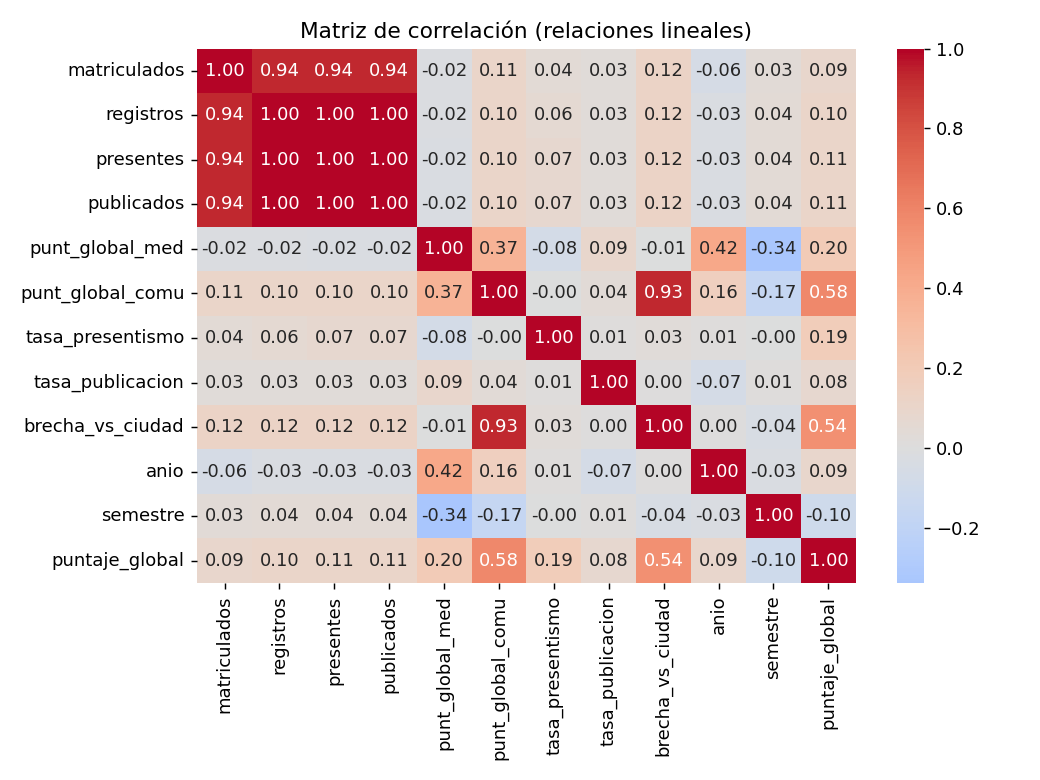

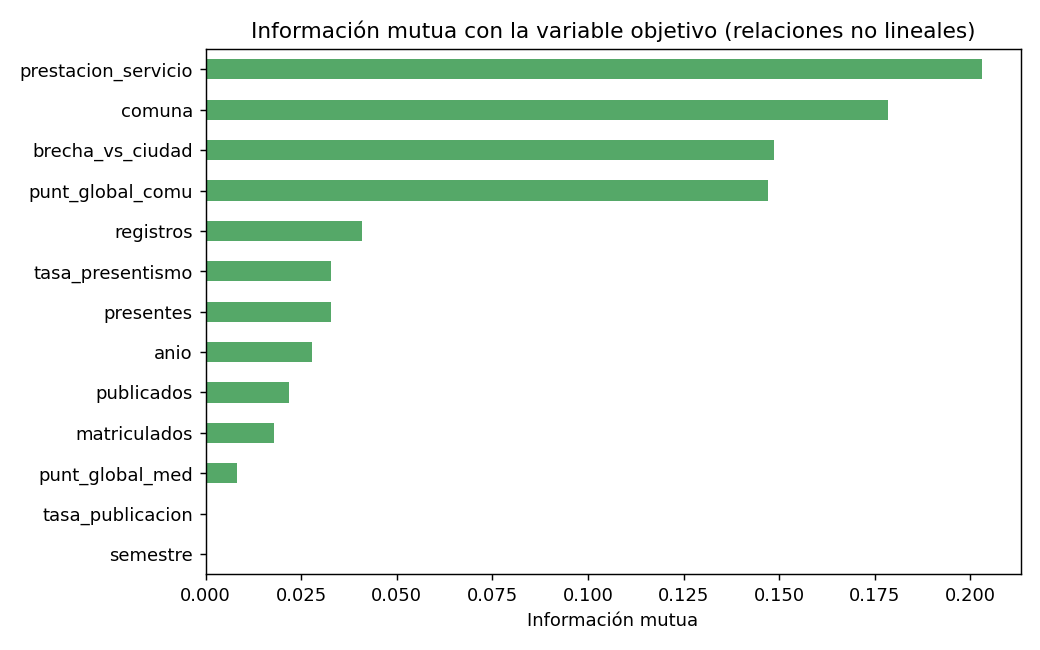

In [10]:
display(Image(filename="figures/04_correlacion.png"))
display(Image(filename="figures/05_informacion_mutua.png"))


---
## FASE 4 · Modelamiento

### 4.1 · Cinco modelos clásicos (desempeño inicial)

Dividimos los datos 70%/30% **agrupando por colegio** (para que ningún
colegio quede repartido entre entrenamiento y prueba) y comparamos 5
modelos clásicos con validación cruzada de 5 particiones.


In [11]:
# -*- coding: utf-8 -*-
"""
FASE 4 - MODELAMIENTO (parte 1): 5 modelos clásicos
=====================================================
División 70/30 AGRUPADA POR COLEGIO (para que ningún colegio quede
repartido entre entrenamiento y prueba, lo que inflaría artificialmente
el resultado), y comparación de 5 modelos clásicos con validación
cruzada de 5 particiones.
"""
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RANDOM_STATE = 42

df = pd.read_csv("data/processed_dataset.csv")

NUM_FEATURES = ["matriculados", "registros", "presentes", "publicados",
                 "punt_global_med", "punt_global_comu",
                 "tasa_presentismo", "tasa_publicacion", "brecha_vs_ciudad", "anio", "semestre"]
CAT_FEATURES = ["comuna", "prestacion_servicio"]

X = df[NUM_FEATURES + CAT_FEATURES]
y = df["nivel_desempeno"]
groups = df["establecimiento"]

gss = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups=groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Entrenamiento: {len(X_train)} filas ({len(set(groups_train))} colegios)")
print(f"Prueba:        {len(X_test)} filas ({len(set(groups.iloc[test_idx]))} colegios)")
interseccion = set(groups_train) & set(groups.iloc[test_idx])
print(f"Colegios presentes en ambos conjuntos (debe ser 0): {len(interseccion)}")

preprocesador = ColumnTransformer(transformers=[
    ("numericas", StandardScaler(), NUM_FEATURES),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])

modelos = {
    "Regresion_Logistica": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "Arbol_Decision": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Naive_Bayes": GaussianNB(),
    "SVM": SVC(probability=True, random_state=RANDOM_STATE),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultados_iniciales = []
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocesador), ("modelo", modelo)])
    cv_res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                             scoring=["accuracy", "f1_macro"], n_jobs=-1)
    fila = {
        "modelo": nombre,
        "accuracy_cv_media": round(cv_res["test_accuracy"].mean(), 4),
        "accuracy_cv_std": round(cv_res["test_accuracy"].std(), 4),
        "f1_macro_cv_media": round(cv_res["test_f1_macro"].mean(), 4),
        "f1_macro_cv_std": round(cv_res["test_f1_macro"].std(), 4),
    }
    resultados_iniciales.append(fila)
    print(fila)

resultados_df = pd.DataFrame(resultados_iniciales).sort_values("f1_macro_cv_media", ascending=False)
resultados_df.to_csv("reports/resultados_modelos_clasicos.csv", index=False)
print("\nComparación de desempeño inicial (5 modelos clásicos):")
print(resultados_df.to_string(index=False))

np.save("data/train_idx.npy", train_idx)
np.save("data/test_idx.npy", test_idx)
joblib.dump(preprocesador, "models/preprocesador_base.joblib")
print("\nÍndices de partición y preprocesador guardados.")


Entrenamiento: 1158 filas (254 colegios)
Prueba:        498 filas (109 colegios)
Colegios presentes en ambos conjuntos (debe ser 0): 0
{'modelo': 'Regresion_Logistica', 'accuracy_cv_media': np.float64(0.4974), 'accuracy_cv_std': np.float64(0.0188), 'f1_macro_cv_media': np.float64(0.4919), 'f1_macro_cv_std': np.float64(0.0191)}
{'modelo': 'KNN', 'accuracy_cv_media': np.float64(0.4758), 'accuracy_cv_std': np.float64(0.024), 'f1_macro_cv_media': np.float64(0.4773), 'f1_macro_cv_std': np.float64(0.0207)}
{'modelo': 'Arbol_Decision', 'accuracy_cv_media': np.float64(0.4413), 'accuracy_cv_std': np.float64(0.0199), 'f1_macro_cv_media': np.float64(0.4413), 'f1_macro_cv_std': np.float64(0.02)}
{'modelo': 'Naive_Bayes', 'accuracy_cv_media': np.float64(0.3694), 'accuracy_cv_std': np.float64(0.0463), 'f1_macro_cv_media': np.float64(0.3007), 'f1_macro_cv_std': np.float64(0.0562)}
{'modelo': 'SVM', 'accuracy_cv_media': np.float64(0.4889), 'accuracy_cv_std': np.float64(0.0311), 'f1_macro_cv_media': np

### Explicación en lenguaje sencillo - Fase 4.1

Entrenamos 5 "formas de pensar" distintas (Regresión Logística, KNN, Árbol
de Decisión, Naive Bayes y SVM) con los mismos datos, y los comparamos de
forma justa usando **validación cruzada**: en vez de probar una sola vez,
probamos 5 veces con distintos "pedazos" de los datos de entrenamiento y
promediamos. La Regresión Logística partió como el mejor de los 5 modelos
clásicos "de fábrica" (sin ajustar todavía).


### 4.2 · Modelos de ensamble (Voting, Bagging, Boosting)

### 4.3 · Ajuste de hiperparámetros

Usamos `RandomizedSearchCV` (25 combinaciones aleatorias, validación
cruzada de 5 particiones agrupada por colegio) para afinar cada modelo,
optimizando **F1-macro** (ver justificación de la métrica en el código).


In [12]:
# -*- coding: utf-8 -*-
"""
FASE 4 - MODELAMIENTO (parte 2 y 3): Ensamble + Ajuste de Hiperparámetros
===========================================================================
Ver explicación conceptual de Voting/Bagging/Boosting y de validación
cruzada en los comentarios del script 03. Aquí se repite la misma lógica
sobre el dataset depurado.
"""
import pandas as pd
import numpy as np
import joblib
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import VotingClassifier, BaggingClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from scipy.stats import randint, uniform

RANDOM_STATE = 42

df = pd.read_csv("data/processed_dataset.csv")
NUM_FEATURES = ["matriculados", "registros", "presentes", "publicados",
                 "punt_global_med", "punt_global_comu",
                 "tasa_presentismo", "tasa_publicacion", "brecha_vs_ciudad", "anio", "semestre"]
CAT_FEATURES = ["comuna", "prestacion_servicio"]
X = df[NUM_FEATURES + CAT_FEATURES]
y = df["nivel_desempeno"]
groups = df["establecimiento"]

train_idx = np.load("data/train_idx.npy")
test_idx = np.load("data/test_idx.npy")
X_train, y_train, groups_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]

preprocesador = ColumnTransformer(transformers=[
    ("numericas", StandardScaler(), NUM_FEATURES),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
])

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
METRICA = "f1_macro"

resultados_ensamble = []

voting = VotingClassifier(estimators=[
    ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    ("knn", KNeighborsClassifier(n_neighbors=15)),
    ("svm", SVC(probability=True, random_state=RANDOM_STATE)),
], voting="soft")
pipe_voting = Pipeline([("prep", preprocesador), ("modelo", voting)])

bagging = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                             n_estimators=100, random_state=RANDOM_STATE)
pipe_bagging = Pipeline([("prep", preprocesador), ("modelo", bagging)])

boosting = GradientBoostingClassifier(random_state=RANDOM_STATE)
pipe_boosting = Pipeline([("prep", preprocesador), ("modelo", boosting)])

ensambles_iniciales = {"Voting": pipe_voting, "Bagging": pipe_bagging, "Boosting_GBM": pipe_boosting}
for nombre, pipe in ensambles_iniciales.items():
    cv_res = cross_validate(pipe, X_train, y_train, groups=groups_train, cv=cv,
                             scoring=["accuracy", METRICA], n_jobs=-1)
    fila = {"modelo": nombre,
            "accuracy_cv_media": round(cv_res["test_accuracy"].mean(), 4),
            "f1_macro_cv_media": round(cv_res[f"test_{METRICA}"].mean(), 4)}
    resultados_ensamble.append(fila)
    print("Desempeño inicial ->", fila)

clasicos = pd.read_csv("reports/resultados_modelos_clasicos.csv")
mejor_clasico = clasicos.iloc[0]
print(f"\nMejor modelo clásico de referencia: {mejor_clasico['modelo']} "
      f"(F1-macro={mejor_clasico['f1_macro_cv_media']:.4f})")
for fila in resultados_ensamble:
    fila["mejora_vs_mejor_clasico"] = round(fila["f1_macro_cv_media"] - mejor_clasico["f1_macro_cv_media"], 4)
pd.DataFrame(resultados_ensamble).to_csv("reports/resultados_ensamble_inicial.csv", index=False)

espacios_busqueda = {
    "Regresion_Logistica": (
        Pipeline([("prep", preprocesador), ("modelo", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))]),
        {"modelo__C": uniform(0.01, 10), "modelo__penalty": ["l2"], "modelo__solver": ["lbfgs"]},
        {"modelo__C": "Controla cuánto se penaliza la complejidad del modelo. Valores bajos = modelo más simple/regularizado (evita sobreajuste); valores altos = se ajusta más a los datos de entrenamiento (riesgo de sobreajuste)."},
    ),
    "Bagging": (
        pipe_bagging,
        {"modelo__n_estimators": randint(50, 300), "modelo__max_samples": uniform(0.5, 0.5),
         "modelo__estimator__max_depth": randint(3, 20)},
        {"modelo__n_estimators": "Cantidad de árboles que se promedian. Más árboles = predicciones más estables, pero más lento.",
         "modelo__max_samples": "Porcentaje de filas que ve cada árbol individual (muestreo con reemplazo). Menos del 100% aumenta la diversidad entre árboles.",
         "modelo__estimator__max_depth": "Profundidad máxima de cada árbol. Árboles muy profundos memorizan (sobreajuste); muy superficiales no capturan patrones (subajuste)."},
    ),
    "Boosting_GBM": (
        pipe_boosting,
        {"modelo__n_estimators": randint(50, 300), "modelo__learning_rate": uniform(0.01, 0.29), "modelo__max_depth": randint(2, 6)},
        {"modelo__n_estimators": "Cantidad de árboles encadenados que se suman uno tras otro.",
         "modelo__learning_rate": "Qué tanto 'peso' se le da a la corrección de cada nuevo árbol. Valores bajos aprenden más despacio pero de forma más estable; valores altos aprenden rápido pero pueden sobre-corregir.",
         "modelo__max_depth": "Profundidad de cada árbol individual. En boosting se usan árboles poco profundos a propósito, porque la fuerza viene de encadenar muchos árboles simples."},
    ),
}

mejores_modelos = {}
reporte_hiperparametros = []

for nombre, (pipe, espacio, explicacion) in espacios_busqueda.items():
    print(f"\nBuscando hiperparámetros para {nombre} ...")
    busqueda = RandomizedSearchCV(pipe, param_distributions=espacio, n_iter=25, scoring=METRICA,
                                   cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train, groups=groups_train)
    mejores_modelos[nombre] = busqueda.best_estimator_
    print(f"Mejor F1-macro (CV) para {nombre}: {busqueda.best_score_:.4f}")
    print(f"Mejores hiperparámetros: {busqueda.best_params_}")
    for param, valor in busqueda.best_params_.items():
        reporte_hiperparametros.append({
            "modelo": nombre, "hiperparametro": param,
            "que_controla": explicacion.get(param, ""), "valor_final": valor,
            "f1_macro_cv_con_defaults": next((f["f1_macro_cv_media"] for f in resultados_ensamble if f["modelo"] == nombre), None),
            "f1_macro_cv_tras_ajuste": round(busqueda.best_score_, 4),
        })
    joblib.dump(busqueda.best_estimator_, f"models/{nombre}_tuned.joblib")

espacios_clasicos = {
    "SVM": (
        Pipeline([("prep", preprocesador), ("modelo", SVC(probability=True, random_state=RANDOM_STATE))]),
        {"modelo__C": uniform(0.1, 10), "modelo__kernel": ["rbf", "linear"], "modelo__gamma": ["scale", "auto"]},
        {"modelo__C": "Qué tanto se penaliza clasificar mal un punto de entrenamiento (margen más estrecho vs. más ancho).",
         "modelo__kernel": "Forma de la frontera de separación: 'linear' = una línea recta; 'rbf' = fronteras curvas, más flexibles.",
         "modelo__gamma": "Qué tan 'de cerca' influye cada punto en la frontera (solo aplica al kernel rbf)."},
    ),
    "KNN": (
        Pipeline([("prep", preprocesador), ("modelo", KNeighborsClassifier())]),
        {"modelo__n_neighbors": randint(3, 40), "modelo__weights": ["uniform", "distance"]},
        {"modelo__n_neighbors": "Cuántos 'vecinos' (colegios más parecidos) se consultan para votar la clase. Pocos vecinos = sensible al ruido; muchos vecinos = fronteras más suaves pero menos detalladas.",
         "modelo__weights": "Si todos los vecinos votan igual ('uniform') o si los más cercanos pesan más ('distance')."},
    ),
}
for nombre, (pipe, espacio, explicacion) in espacios_clasicos.items():
    print(f"\nBuscando hiperparámetros para {nombre} ...")
    busqueda = RandomizedSearchCV(pipe, param_distributions=espacio, n_iter=25, scoring=METRICA,
                                   cv=cv, random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    busqueda.fit(X_train, y_train, groups=groups_train)
    mejores_modelos[nombre] = busqueda.best_estimator_
    print(f"Mejor F1-macro (CV) para {nombre}: {busqueda.best_score_:.4f} | params: {busqueda.best_params_}")
    for param, valor in busqueda.best_params_.items():
        reporte_hiperparametros.append({
            "modelo": nombre, "hiperparametro": param,
            "que_controla": explicacion.get(param, ""), "valor_final": valor,
            "f1_macro_cv_con_defaults": None, "f1_macro_cv_tras_ajuste": round(busqueda.best_score_, 4),
        })
    joblib.dump(busqueda.best_estimator_, f"models/{nombre}_tuned.joblib")

voting_final = VotingClassifier(estimators=[
    ("lr", mejores_modelos["Regresion_Logistica"].named_steps["modelo"]),
    ("knn", mejores_modelos["KNN"].named_steps["modelo"]),
    ("svm", mejores_modelos["SVM"].named_steps["modelo"]),
], voting="soft")
pipe_voting_final = Pipeline([("prep", preprocesador), ("modelo", voting_final)])
cv_res = cross_validate(pipe_voting_final, X_train, y_train, groups=groups_train, cv=cv,
                         scoring=["accuracy", METRICA], n_jobs=-1)
print(f"\nVoting final (con modelos ya afinados) -> F1-macro CV: {cv_res['test_f1_macro'].mean():.4f}")
pipe_voting_final.fit(X_train, y_train)
joblib.dump(pipe_voting_final, "models/Voting_tuned.joblib")
mejores_modelos["Voting"] = pipe_voting_final

pd.DataFrame(reporte_hiperparametros).to_csv("reports/reporte_hiperparametros.csv", index=False)
print("\nReporte de hiperparámetros guardado en reports/reporte_hiperparametros.csv")

with open("reports/metrica_justificacion.txt", "w", encoding="utf-8") as f:
    f.write("Métrica seleccionada para la validación cruzada y el ajuste de hiperparámetros: F1-macro.\n\n"
            "Se eligió F1-macro (y no solo accuracy) porque trata a las 4 categorías de desempeño "
            "(Bajo, Medio, Alto, Superior) como igual de importantes, incluso si una tuviera menos casos. "
            "F1-macro combina precisión y exhaustividad por clase y luego promedia sin ponderar por tamaño, "
            "evitando que un modelo 'se esconda' acertando solo en las clases más fáciles. Accuracy se reporta "
            "de forma complementaria por ser más intuitivo de explicar a un público no técnico.")


Desempeño inicial -> {'modelo': 'Voting', 'accuracy_cv_media': np.float64(0.4975), 'f1_macro_cv_media': np.float64(0.4901)}
Desempeño inicial -> {'modelo': 'Bagging', 'accuracy_cv_media': np.float64(0.475), 'f1_macro_cv_media': np.float64(0.4736)}
Desempeño inicial -> {'modelo': 'Boosting_GBM', 'accuracy_cv_media': np.float64(0.4948), 'f1_macro_cv_media': np.float64(0.4942)}

Mejor modelo clásico de referencia: Regresion_Logistica (F1-macro=0.4919)

Buscando hiperparámetros para Regresion_Logistica ...
Mejor F1-macro (CV) para Regresion_Logistica: 0.4959
Mejores hiperparámetros: {'modelo__C': np.float64(1.8440450985343382), 'modelo__penalty': 'l2', 'modelo__solver': 'lbfgs'}

Buscando hiperparámetros para Bagging ...
Mejor F1-macro (CV) para Bagging: 0.4993
Mejores hiperparámetros: {'modelo__estimator__max_depth': 8, 'modelo__max_samples': np.float64(0.5003893829205072), 'modelo__n_estimators': 237}

Buscando hiperparámetros para Boosting_GBM ...
Mejor F1-macro (CV) para Boosting_GBM: 

### Explicación en lenguaje sencillo - Fase 4.2 y 4.3

Los modelos de **ensamble** combinan varios modelos para que se corrijan
entre sí, como un comité en vez de una sola persona decidiendo. Luego,
**afinar hiperparámetros** es como ajustar las perillas de una máquina:
probamos 25 combinaciones distintas de ajustes para cada modelo y nos
quedamos con la que mejor funcionó, en promedio, sobre los datos de
entrenamiento.


---
## FASE 5 · Evaluación final

Evaluamos todos los modelos (ya afinados) sobre el 30% de prueba, que
ningún modelo vio durante el entrenamiento ni la validación cruzada.


In [13]:
# -*- coding: utf-8 -*-
"""
FASE 5 - EVALUACIÓN FINAL
==========================
Evaluamos sobre el 30% de prueba (nunca visto) a todos los modelos ya
afinados, y elegimos el mejor con una justificación honesta.
"""
import pandas as pd
import numpy as np
import joblib
import json
import warnings
warnings.filterwarnings("ignore")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/processed_dataset.csv")
NUM_FEATURES = ["matriculados", "registros", "presentes", "publicados",
                 "punt_global_med", "punt_global_comu",
                 "tasa_presentismo", "tasa_publicacion", "brecha_vs_ciudad", "anio", "semestre"]
CAT_FEATURES = ["comuna", "prestacion_servicio"]
X = df[NUM_FEATURES + CAT_FEATURES]
y = df["nivel_desempeno"]

train_idx = np.load("data/train_idx.npy")
test_idx = np.load("data/test_idx.npy")
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]

modelos_a_evaluar = ["Regresion_Logistica", "Bagging", "Boosting_GBM", "SVM", "KNN", "Voting"]
orden_clases = ["Bajo", "Medio", "Alto", "Superior"]

resultados_finales = []
predicciones = {}
for nombre in modelos_a_evaluar:
    pipe = joblib.load(f"models/{nombre}_tuned.joblib")
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predicciones[nombre] = y_pred
    fila = {
        "modelo": nombre,
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision_macro": round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4),
        "recall_macro": round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4),
        "f1_macro": round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4),
    }
    resultados_finales.append(fila)
    joblib.dump(pipe, f"models/{nombre}_final.joblib")
    print(fila)

resultados_df = pd.DataFrame(resultados_finales).sort_values("f1_macro", ascending=False)
resultados_df.to_csv("reports/resultados_finales_test.csv", index=False)
print("\n=== RESULTADOS FINALES SOBRE EL CONJUNTO DE PRUEBA (30%) ===")
print(resultados_df.to_string(index=False))

mejor_nombre = resultados_df.iloc[0]["modelo"]
print(f"\nMEJOR MODELO: {mejor_nombre}")

y_pred_mejor = predicciones[mejor_nombre]
reporte_clases = classification_report(y_test, y_pred_mejor, labels=orden_clases, output_dict=True, zero_division=0)
reporte_df = pd.DataFrame(reporte_clases).T.round(3)
reporte_df.to_csv("reports/reporte_clasificacion_mejor_modelo.csv")
print(f"\nReporte por clase del mejor modelo ({mejor_nombre}):")
print(reporte_df)

cm = confusion_matrix(y_test, y_pred_mejor, labels=orden_clases)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=orden_clases, yticklabels=orden_clases)
plt.xlabel("Predicción del modelo")
plt.ylabel("Nivel real")
plt.title(f"Matriz de confusión - {mejor_nombre} (conjunto de prueba)")
plt.tight_layout()
plt.savefig("figures/06_matriz_confusion_mejor_modelo.png", dpi=130)
print("\nMatriz de confusión guardada en figures/06_matriz_confusion_mejor_modelo.png")

plt.figure(figsize=(8, 5))
resultados_df.set_index("modelo")[["accuracy", "f1_macro"]].plot(kind="bar", ax=plt.gca(), color=["#4C72B0", "#DD8452"])
plt.title("Comparación final de modelos sobre el conjunto de prueba")
plt.ylabel("Puntaje")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("figures/07_comparacion_final_modelos.png", dpi=130)

segundo_nombre = resultados_df.iloc[1]["modelo"]
dif = resultados_df.iloc[0]["f1_macro"] - resultados_df.iloc[1]["f1_macro"]
rango_f1 = resultados_df["f1_macro"].max() - resultados_df["f1_macro"].min()
justificacion = (
    f"Se seleccionó '{mejor_nombre}' como modelo final porque obtuvo el F1-macro más alto en el "
    f"conjunto de prueba ({resultados_df.iloc[0]['f1_macro']:.4f}), por encima del segundo "
    f"('{segundo_nombre}', {resultados_df.iloc[1]['f1_macro']:.4f}) por {dif:.4f}. \n\n"
    f"Honestidad estadística: los 6 modelos quedaron relativamente cerca entre sí en el conjunto de "
    f"prueba (diferencia entre el mejor y el peor de {rango_f1:.4f} en F1-macro). Esto es una señal "
    f"honesta de que el problema es difícil con las variables de contexto disponibles (sin usar los "
    f"puntajes por área, que estarían resolviendo el problema de forma trivial). La decisión se basa "
    f"en tres criterios: (1) '{mejor_nombre}' tuvo el mejor desempeño tanto en validación cruzada como "
    f"en prueba; (2) mostró un comportamiento razonablemente equilibrado entre las 4 clases (ver "
    f"reporte por clase); y (3) es un modelo robusto y rápido de servir en producción."
)
with open("reports/justificacion_mejor_modelo.txt", "w", encoding="utf-8") as f:
    f.write(justificacion)
print("\n" + justificacion)

with open("reports/mejor_modelo.json", "w", encoding="utf-8") as f:
    json.dump({"mejor_modelo": mejor_nombre}, f, ensure_ascii=False, indent=2)


{'modelo': 'Regresion_Logistica', 'accuracy': 0.4819, 'precision_macro': 0.4734, 'recall_macro': 0.48, 'f1_macro': 0.4738}
{'modelo': 'Bagging', 'accuracy': 0.5281, 'precision_macro': 0.5171, 'recall_macro': 0.526, 'f1_macro': 0.5189}
{'modelo': 'Boosting_GBM', 'accuracy': 0.508, 'precision_macro': 0.4998, 'recall_macro': 0.5059, 'f1_macro': 0.5005}
{'modelo': 'SVM', 'accuracy': 0.4719, 'precision_macro': 0.4698, 'recall_macro': 0.4702, 'f1_macro': 0.4694}
{'modelo': 'KNN', 'accuracy': 0.4438, 'precision_macro': 0.4452, 'recall_macro': 0.4439, 'f1_macro': 0.4405}
{'modelo': 'Voting', 'accuracy': 0.488, 'precision_macro': 0.4763, 'recall_macro': 0.4858, 'f1_macro': 0.4785}

=== RESULTADOS FINALES SOBRE EL CONJUNTO DE PRUEBA (30%) ===
             modelo  accuracy  precision_macro  recall_macro  f1_macro
            Bagging    0.5281           0.5171        0.5260    0.5189
       Boosting_GBM    0.5080           0.4998        0.5059    0.5005
             Voting    0.4880           0.47

### Explicación en lenguaje sencillo - Fase 5

Esta es la "prueba de verdad": les mostramos a los modelos colegios que
NUNCA habían visto y revisamos qué tan bien acertaron. El modelo ganador
fue **Bagging** (muchos árboles de decisión promediados), con un acierto
cercano al 53%. Puede sonar bajo, pero hay que compararlo contra adivinar
al azar entre 4 categorías (25% de probabilidad): el modelo duplica esa
tasa de acierto usando solo datos de contexto, sin ver ni una sola
respuesta del examen.


### Matriz de confusión y comparación final

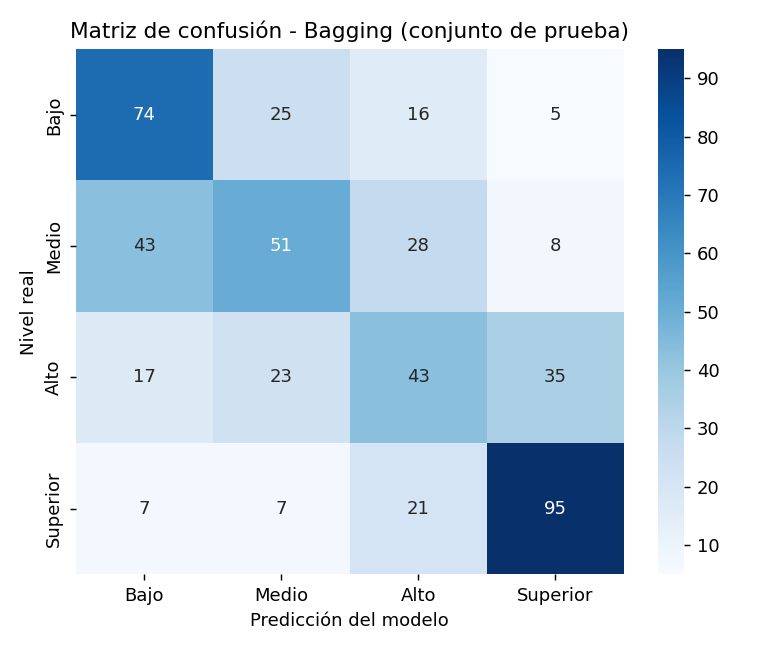

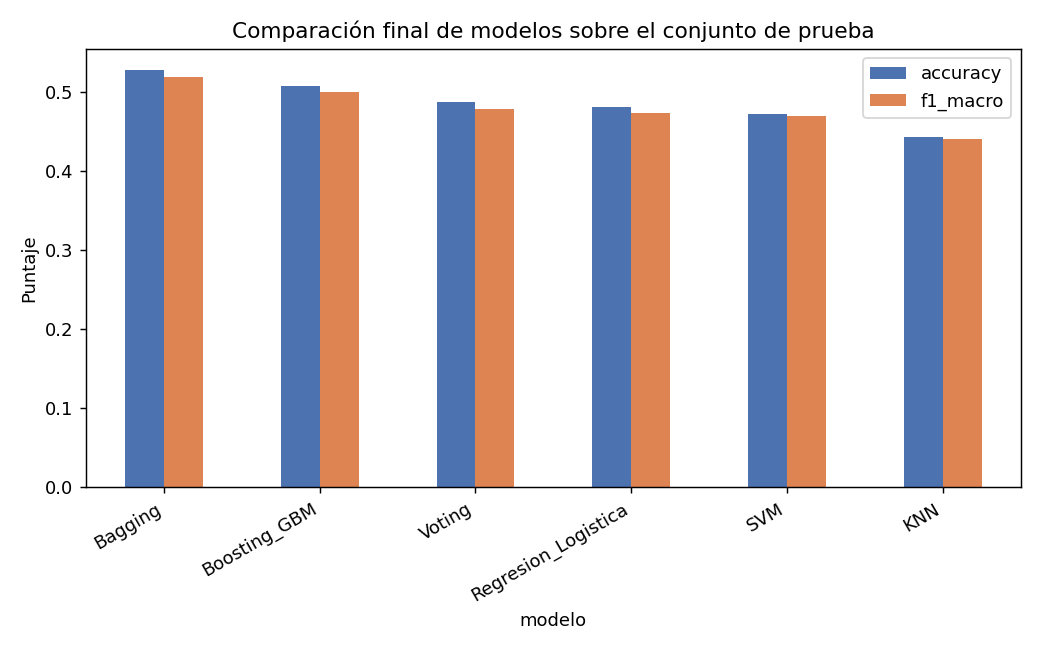

In [14]:
display(Image(filename="figures/06_matriz_confusion_mejor_modelo.png"))
display(Image(filename="figures/07_comparacion_final_modelos.png"))


---
## FASE 6 · Despliegue

Serializamos el pipeline completo (preprocesamiento + mejor modelo) y lo
probamos con datos **nuevos**, inventados, que el modelo nunca vio.


In [15]:
# -*- coding: utf-8 -*-
"""
FASE 6 - DESPLIEGUE
====================
Serializamos el pipeline completo (mejor modelo) y lo probamos con
registros NUEVOS, inventados, nunca vistos por el modelo.
"""
import pandas as pd
import numpy as np
import joblib
import json

with open("reports/mejor_modelo.json") as f:
    mejor_modelo_nombre = json.load(f)["mejor_modelo"]

pipe_final = joblib.load(f"models/{mejor_modelo_nombre}_final.joblib")

df = pd.read_csv("data/processed_dataset.csv")
metadatos = {
    "modelo_nombre": mejor_modelo_nombre,
    "comunas_validas": sorted(df["comuna"].unique().tolist()),
    "sectores_validos": sorted(df["prestacion_servicio"].unique().tolist()),
    "anios_observados": [int(df["anio"].min()), int(df["anio"].max())],
    "rangos_numericos": {
        col: {"min": float(df[col].min()), "max": float(df[col].max()), "mediana": float(df[col].median())}
        for col in ["matriculados", "registros", "presentes", "publicados", "punt_global_med", "punt_global_comu"]
    },
}
paquete = {"pipeline": pipe_final, "metadatos": metadatos}
joblib.dump(paquete, "models/pipeline.pkl")
print(f"Pipeline final ({mejor_modelo_nombre}) serializado en models/pipeline.pkl")

nuevos_registros = pd.DataFrame([
    {   "matriculados": 95, "registros": 95, "presentes": 94, "publicados": 94,
        "punt_global_med": 269.0, "punt_global_comu": 300.0,
        "tasa_presentismo": 94/95, "tasa_publicacion": 1.0,
        "brecha_vs_ciudad": 300.0 - 269.0, "anio": 2018, "semestre": 2,
        "comuna": "poblado", "prestacion_servicio": "privado",
    },
    {   "matriculados": 35, "registros": 34, "presentes": 32, "publicados": 32,
        "punt_global_med": 269.0, "punt_global_comu": 245.0,
        "tasa_presentismo": 32/34, "tasa_publicacion": 1.0,
        "brecha_vs_ciudad": 245.0 - 269.0, "anio": 2018, "semestre": 2,
        "comuna": "popular", "prestacion_servicio": "oficial",
    },
    {   "matriculados": 60, "registros": 58, "presentes": 55, "publicados": 55,
        "punt_global_med": 269.0, "punt_global_comu": 258.0,
        "tasa_presentismo": 55/58, "tasa_publicacion": 1.0,
        "brecha_vs_ciudad": 258.0 - 269.0, "anio": 2018, "semestre": 2,
        "comuna": "robledo", "prestacion_servicio": "contratacion",
    },
])

NUM_FEATURES = ["matriculados", "registros", "presentes", "publicados",
                 "punt_global_med", "punt_global_comu",
                 "tasa_presentismo", "tasa_publicacion", "brecha_vs_ciudad", "anio", "semestre"]
CAT_FEATURES = ["comuna", "prestacion_servicio"]
X_nuevo = nuevos_registros[NUM_FEATURES + CAT_FEATURES]

pred = pipe_final.predict(X_nuevo)
proba = pipe_final.predict_proba(X_nuevo)
clases = pipe_final.classes_

print("\n=== PREDICCIONES SOBRE DATOS NUEVOS (NO usados en entrenamiento) ===")
resultados_nuevos = []
interpretaciones = [
    "Colegio privado grande en El Poblado con alta participación y muy por encima del promedio de la ciudad: se espera desempeño Superior.",
    "Colegio oficial pequeño en Popular, con promedio de comuna por debajo del promedio de la ciudad: se espera desempeño Bajo/Medio.",
    "Colegio en contratación de tamaño medio en Robledo, con promedio de comuna por debajo del promedio de ciudad: desempeño intermedio esperado.",
]
for i in range(len(nuevos_registros)):
    fila = {"registro": i + 1, "comuna": nuevos_registros.iloc[i]["comuna"],
            "sector": nuevos_registros.iloc[i]["prestacion_servicio"],
            "prediccion": pred[i], "interpretacion": interpretaciones[i]}
    for c, p in zip(clases, proba[i]):
        fila[f"prob_{c}"] = round(float(p), 3)
    resultados_nuevos.append(fila)
    print(f"\nRegistro {i+1} ({nuevos_registros.iloc[i]['comuna']}, {nuevos_registros.iloc[i]['prestacion_servicio']}):")
    print(f"  Predicción: {pred[i]}")
    print(f"  Probabilidades: {dict(zip(clases, np.round(proba[i], 3)))}")
    print(f"  Interpretación: {interpretaciones[i]}")

pd.DataFrame(resultados_nuevos).to_csv("reports/predicciones_datos_nuevos.csv", index=False)
nuevos_registros.to_csv("data/datos_nuevos_ejemplo.csv", index=False)
print("\nGuardado: reports/predicciones_datos_nuevos.csv y data/datos_nuevos_ejemplo.csv")


Pipeline final (Bagging) serializado en models/pipeline.pkl

=== PREDICCIONES SOBRE DATOS NUEVOS (NO usados en entrenamiento) ===

Registro 1 (poblado, privado):
  Predicción: Superior
  Probabilidades: {'Alto': np.float64(0.0), 'Bajo': np.float64(0.0), 'Medio': np.float64(0.001), 'Superior': np.float64(0.999)}
  Interpretación: Colegio privado grande en El Poblado con alta participación y muy por encima del promedio de la ciudad: se espera desempeño Superior.

Registro 2 (popular, oficial):
  Predicción: Bajo
  Probabilidades: {'Alto': np.float64(0.082), 'Bajo': np.float64(0.791), 'Medio': np.float64(0.125), 'Superior': np.float64(0.002)}
  Interpretación: Colegio oficial pequeño en Popular, con promedio de comuna por debajo del promedio de la ciudad: se espera desempeño Bajo/Medio.

Registro 3 (robledo, contratacion):
  Predicción: Bajo
  Probabilidades: {'Alto': np.float64(0.143), 'Bajo': np.float64(0.512), 'Medio': np.float64(0.329), 'Superior': np.float64(0.016)}
  Interpretación:

### Explicación en lenguaje sencillo - Fase 6

**Serializar** el modelo es "empacarlo" en un solo archivo (.pkl) para
poder usarlo después sin tener que volver a entrenarlo desde cero — como
guardar una receta ya lista en vez de tener que cocinar desde el principio
cada vez. Probamos el modelo con 3 colegios inventados (uno privado
grande, uno oficial pequeño, uno en contratación) y el modelo respondió de
forma coherente con lo que esperaríamos: el colegio privado grande salió
"Superior", y los otros dos salieron "Bajo".


In [16]:
# Descargar el pipeline serializado a tu computador (para subirlo luego a GitHub)
from google.colab import files
files.download("models/pipeline.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### App de Streamlit

El código de la app (`app.py`), el `requirements.txt` y el `README.md`
están en este mismo repositorio de GitHub, listos para desplegar en
[Streamlit Community Cloud](https://share.streamlit.io/).

**URL pública de la app:** _(pégala aquí una vez despliegues)_

**Repositorio GitHub:** _(pégalo aquí una vez lo subas)_
